# Wind & Solar Resource Assessment RAG Assistant

End-to-end pipeline: document ingestion, embedding, hybrid retrieval, grounded generation and retrieval evaluation.

## 1. Setup

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")  # run from the project root

%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import getpass
import numpy as np
from sentence_transformers import SentenceTransformer

import rag
from rag import RAGAssistant, build_index, chunk_pages, load_documents

if not os.environ.get("HF_TOKEN"):
    os.environ["HF_TOKEN"] = getpass.getpass("Hugging Face token (Enter to use local model): ").strip()

c:\Users\afree\analysis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load and chunk documents

In [3]:
pages = load_documents(rag.DATA_DIR)
chunks = chunk_pages(pages, rag.CHUNK_SIZE, rag.CHUNK_OVERLAP)

print(f"Files: {len({p['source'] for p in pages})} | Pages: {len(pages)} | Chunks: {len(chunks)}")
print(f"Chunk size: {rag.CHUNK_SIZE} chars, overlap: {rag.CHUNK_OVERLAP}")

Files: 9 | Pages: 9 | Chunks: 31
Chunk size: 500 chars, overlap: 100


## 3. Embeddings

In [4]:
embedder = SentenceTransformer(rag.EMBED_MODEL)

sentences = [
    "Wind speed increases with height above the ground.",
    "Higher up, the wind blows faster.",
    "Solar panels lose output when they get dusty.",
]
vecs = embedder.encode(sentences, normalize_embeddings=True)
print("Embedding dimension:", vecs.shape[1])
for s, sim in zip(sentences, vecs @ vecs[0]):
    print(f"{sim:.2f}  {s}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1903.84it/s]


Embedding dimension: 384
1.00  Wind speed increases with height above the ground.
0.91  Higher up, the wind blows faster.
0.61  Solar panels lose output when they get dusty.


## 4. Build index

In [5]:
import faiss, pickle

index = build_index(chunks, embedder)
os.makedirs(rag.INDEX_DIR, exist_ok=True)
faiss.write_index(index, os.path.join(rag.INDEX_DIR, "index.faiss"))
with open(os.path.join(rag.INDEX_DIR, "chunks.pkl"), "wb") as f:
    pickle.dump(chunks, f)

assistant = RAGAssistant(embedder=embedder)
print("Indexed vectors:", index.ntotal)

Indexed vectors: 31


## 5. Retrieval

In [6]:
def show_hits(hits):
    for n, (c, s) in enumerate(hits, 1):
        print(f"[{n}] {s:.2f}  {c['source']}  |  {c['text'][:90]}...")

query = "How do I convert wind speed measured at 80 m to hub height?"
print("Vector search:"); show_hits(assistant.vector_search(query, 3))
print("\nHybrid search:"); show_hits(assistant.hybrid_search(query, 3))

Vector search:
[1] 0.77  01_wind_shear.txt  |  Wind shear describes how wind speed changes with height above the ground. Near the ground,...
[2] 0.75  09_thoothukudi_ridge_site_report.txt  |  ng alpha = 0.18, the long-term mean wind speed at the 120 m hub height is 7.1 m/s. Shear i...
[3] 0.75  09_thoothukudi_ridge_site_report.txt  |  ts: An 80 m met mast (Mast TR-01) recorded data from March 2023 to February 2025, and a gr...

Hybrid search:
[1] 0.77  01_wind_shear.txt  |  Wind shear describes how wind speed changes with height above the ground. Near the ground,...
[2] 0.75  09_thoothukudi_ridge_site_report.txt  |  ts: An 80 m met mast (Mast TR-01) recorded data from March 2023 to February 2025, and a gr...
[3] 0.75  05_lidar_vs_met_mast.txt  |  Wind can be measured with a met mast (a tower with cup anemometers and wind vanes) or with...


## 6. Generation: LLM alone vs RAG

`Thoothukudi Ridge` is a fictional project that exists only in the corpus.

In [7]:
question = "What is the P50 net energy and hub-height wind speed of the Thoothukudi Ridge Wind Project?"

llm_only = assistant.generate([
    {"role": "system", "content": "You are a wind energy engineer."},
    {"role": "user", "content": question},
])
rag_answer, hits = assistant.answer(question)

print("Model:", assistant.llm_name)
print("\nLLM only:\n", llm_only)
print("\nRAG:\n", rag_answer)
print("\nSources:"); show_hits(hits)

Loading weights: 100%|██████████| 290/290 [00:01<00:00, 272.27it/s]


Model: Qwen/Qwen2.5-0.5B-Instruct

LLM only:
 I'm sorry, but I don't have specific information about the Thoothukudi Ridge Wind Project or its P50 Net Energy and Hub-Height Wind Speeds. These details would typically be provided by the project developers or relevant government agencies. Without access to official data or reports from these sources, I can't provide accurate numerical values for the P50 Net Energy and Hub-Height Wind Speeds of this particular wind project. For more detailed information, you may want to consult with the project management team or contact the relevant authorities directly.

RAG:
 P50 net energy of the Thoothukudi Ridge Wind Project is 312 GWh/yr, and the hub height is 120 m.

Sources:
[1] 0.82  09_thoothukudi_ridge_site_report.txt  |  FICTIONAL PROJECT REPORT - created for learning purposes only. Thoothukudi Ridge Wind Proj...
[2] 0.68  06_energy_yield_p50_p90.txt  |  An energy yield assessment estimates how much electricity a wind farm will produce each ye

## 7. Sample questions

In [8]:
for q in [
    "Why do lenders use P90 instead of P50?",
    "Which long-term reference was used at Thoothukudi Ridge and how good was the correlation?",
    "What was the data availability of mast TR-01?",
]:
    ans, hits = assistant.answer(q)
    print(f"Q: {q}\nA: {ans}\nSources: {', '.join(sorted({c['source'] for c, _ in hits}))}\n")

Q: Why do lenders use P90 instead of P50?
A: Lenders use P90 instead of P50 because it provides a more conservative estimate of the project's potential profitability, especially in scenarios where there is significant uncertainty due to factors such as weather conditions, plant performance, and market fluctuations.
Sources: 02_turbulence_intensity.txt, 06_energy_yield_p50_p90.txt, 09_thoothukudi_ridge_site_report.txt

Q: Which long-term reference was used at Thoothukudi Ridge and how good was the correlation?
A: [1] (source: 09_thoothukudi_ridge_ridge_site_report.txt, page 1)

Long-term reference: ERA5

R squared: 0.86
Sources: 03_mcp_long_term_correction.txt, 09_thoothukudi_ridge_site_report.txt

Q: What was the data availability of mast TR-01?
A: [1] (source: 09_thoothukudi_ridge_site_report.txt, page 1)

The data availability of the 80 m met mast (Mast TR-01) after filtering was 96.4 percent.
Sources: 05_lidar_vs_met_mast.txt, 09_thoothukudi_ridge_site_report.txt



## 8. Out-of-scope guardrail

Queries below `MIN_SCORE` are refused without calling the LLM.

In [9]:
print(f"MIN_SCORE = {rag.MIN_SCORE}\n")
for q in ["What is turbulence intensity?",
          "How is P90 calculated from P50?",
          "Who won the cricket World Cup in 2011?",
          "Give me a recipe for biryani."]:
    top = assistant.vector_search(q, 1)[0][1]
    ans, _ = assistant.answer(q)
    status = "refused" if ans == rag.NOT_FOUND else "answered"
    print(f"{top:.2f}  {status:<8}  {q}")

MIN_SCORE = 0.5

0.85  answered  What is turbulence intensity?
0.77  answered  How is P90 calculated from P50?
0.45  refused   Who won the cricket World Cup in 2011?
0.52  refused   Give me a recipe for biryani.


## 9. Evaluation

Hit@5 and MRR on 20 labelled questions (`eval/questions.json`), across chunk sizes and search methods.

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1988.07it/s]


Evaluation on 20 questions (k=5)

| Chunk size | Chunks | Hit@5 | MRR |
|---:|---:|---:|---:|
| 200 | 75 | 100% | 0.97 |
| 350 | 43 | 100% | 1.00 |
| 500 | 31 | 100% | 1.00 |
| 800 | 20 | 100% | 0.97 |
| 1200 | 14 | 100% | 0.90 |

Search method (chunk size 350)

| Method | Hit@5 | MRR |
|---|---:|---:|
| Vector (FAISS) | 100% | 1.00 |
| Keyword (BM25) | 100% | 0.95 |
| Hybrid (RRF) | 100% | 1.00 |

Saved eval/results.md and assets/evaluation_results.png


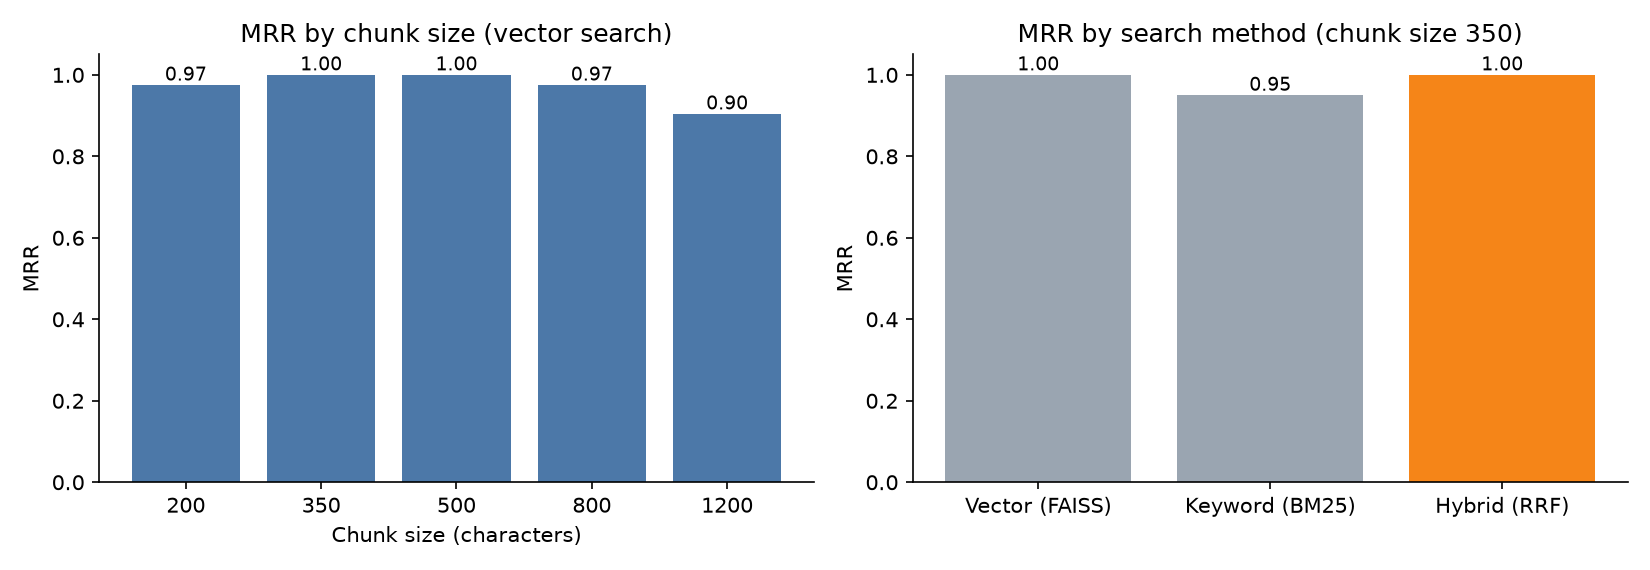

In [10]:
import evaluate
from IPython.display import Image, display

evaluate.main()
display(Image("assets/evaluation_results.png"))

## 10. Web app

In [ ]:
import app
app.demo.launch("share=True")

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
* To create a public link, set `share=True` in `launch()`.


Loading weights: 100%|██████████| 290/290 [00:01<00:00, 237.87it/s]
